# TP2 · Clasificación supervisada — Bank Marketing
## Paso 5 · Conclusiones

Este notebook reúne los resultados de los Pasos 1–4 (no entrena modelos nuevos: lee los resultados guardados en `resultados/`) y responde lo que pide el enunciado:
1. ¿Qué modelos funcionaron mejor y por qué? (relacionado con el EDA y con cómo funciona cada algoritmo)
2. ¿Los datos se ajustan a los supuestos de cada modelo?
3. ¿Qué errores son los más relevantes?
4. Limitaciones del sistema y mejoras.

### 5.1 Resumen del recorrido

| Paso | Qué se hizo | Datos | Resultado clave |
|---|---|---|---|
| **1 · EDA** | Limpieza, split 80/20 estratificado, EDA solo en train | Train | Se elimina `duration` (leakage); desbalance 88.7/11.3; `pdays` → `contactado_antes`; se quitan variables sin poder discriminante y macro redundantes (r > 0.9) → **set B, 14 variables** |
| **2 · Clasificadores** | NB, SVM, KNN y RF por defecto, 5-fold CV estratificada; 4 sets de variables | Train (CV) | Métricas: **Recall** (FN = error más grave) + **ROC-AUC**. Se elige el set B: la ventaja del set completo en RF venía de variables que identifican la fecha de la llamada |
| **3 · Hiperparámetros** | Curvas de validación (train vs. validación) | Train (CV) | RF `max_depth=10`, `n_estimators=50` (AUC 0.744→0.795); KNN `k=301` (0.730→0.784); SVM RBF `C=0.1` (0.699→0.705) |
| **4 · Modelo final** | RF; umbral elegido con predicciones fuera de fold; una sola evaluación en test | Train → **Test** | Umbral 0.083 → **test: AUC 0.806, recall 0.70**, precisión 0.30 (dentro de lo estimado por CV) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import roc_curve, roc_auc_score, precision_score

from tp2_comun import (RESULTADOS, cargar_split, agregar_features, estilo_graficos, guardar,
                       COLORES_MODELO, C_NO, C_YES, C_GRIS)
estilo_graficos()

X_train, y_train = cargar_split("train")
res_def, _ = joblib.load(RESULTADOS / "paso2_cv.joblib")
res_aj, oof_aj = joblib.load(RESULTADOS / "paso3_modelos_ajustados.joblib")
final = joblib.load(RESULTADOS / "modelo_final.joblib")
ORDEN = ["Naive Bayes", "SVM", "KNN", "Random Forest"]

### 5.2 ¿Qué modelo funcionó mejor?
Para comparar **de forma justa** también el recall (que depende del umbral), a cada modelo ajustado se le aplica **su propio umbral óptimo** (punto de la ROC más cercano a (0, 1)), elegido con sus predicciones fuera de fold en train, exactamente igual que se hizo con RF en el Paso 4. *(Todo con train; el test solo se usó para el modelo final.)*

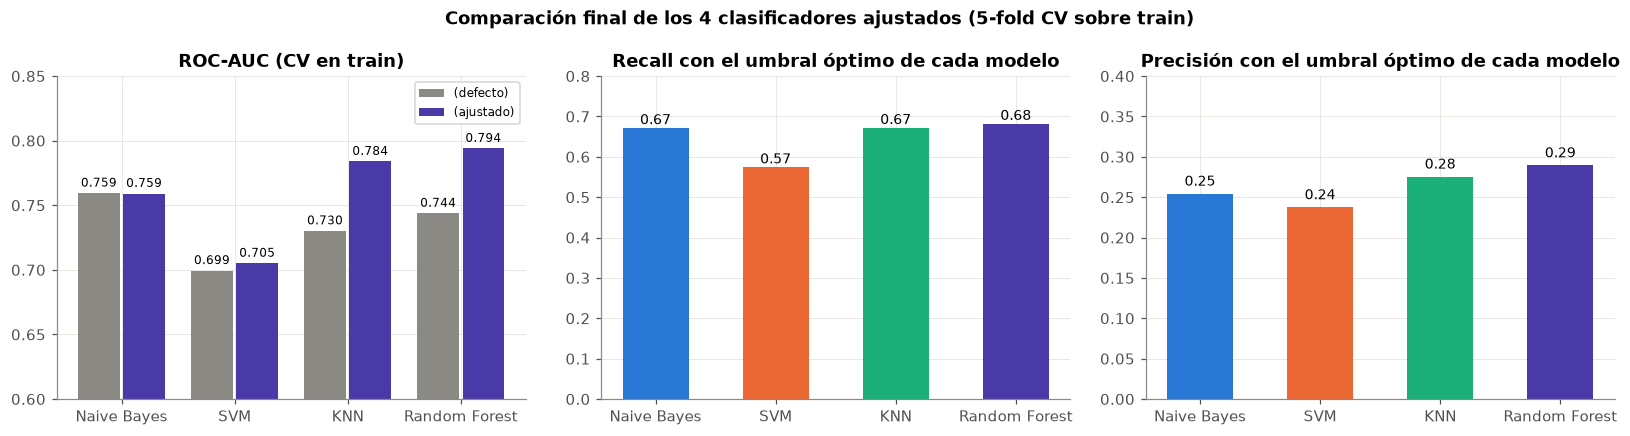

,AUC (defecto),AUC (ajustado),Recall,Precisión,% a llamar
modelo,,,,,
Naive Bayes,0.759,0.759,0.671,0.254,0.297
SVM,0.699,0.705,0.574,0.237,0.272
KNN,0.730,0.784,0.671,0.275,0.275
Random Forest,0.744,0.794,0.681,0.289,0.265


In [2]:
filas = []
for m in ORDEN:
    s = oof_aj[m]["score"]
    fpr, tpr, u = roc_curve(y_train, s)
    i = np.argmin(np.sqrt(fpr**2 + (1 - tpr)**2)[1:]) + 1
    pred = s >= u[i]
    filas.append({"modelo": m,
                  "AUC (defecto)": res_def[res_def.set == "B · EDA"].groupby("modelo")["val_auc"].mean()[m],
                  "AUC (ajustado)": roc_auc_score(y_train, s),
                  "Recall": tpr[i], "Precisión": precision_score(y_train, pred),
                  "% a llamar": pred.mean()})
comp = pd.DataFrame(filas).set_index("modelo")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
x = np.arange(len(ORDEN))
ax = axes[0]
for j, (col, c) in enumerate([("AUC (defecto)", C_GRIS), ("AUC (ajustado)", "#4a3aa7")]):
    ax.bar(x - 0.2 + 0.4 * j, comp[col], width=0.37, color=c, label=col.replace("AUC ", ""))
    for xp, v in zip(x - 0.2 + 0.4 * j, comp[col]): ax.text(xp, v + 0.005, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(x, ORDEN); ax.set(title="ROC-AUC (CV en train)", ylim=(0.6, 0.85)); ax.legend(fontsize=8)
for ax, col, color in [(axes[1], "Recall", C_YES), (axes[2], "Precisión", C_NO)]:
    ax.bar(x, comp[col], width=0.55, color=[COLORES_MODELO[m] for m in ORDEN])
    for xp, v in zip(x, comp[col]): ax.text(xp, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
    ax.set_xticks(x, ORDEN); ax.set(title=f"{col} con el umbral óptimo de cada modelo", ylim=(0, 0.8 if col == "Recall" else 0.4))
fig.suptitle("Comparación final de los 4 clasificadores ajustados (5-fold CV sobre train)", fontweight="bold")
guardar("22_comparacion_final")
comp.round(3)

**Ranking: Random Forest > KNN > Naive Bayes > SVM.** Con el umbral óptimo de cada uno, RF detecta la mayor proporción de interesados (0.68) llamando a la menor proporción de clientes (26.5 %) y con la mejor precisión (0.29). KNN y NB quedan cerca en recall (0.67) pero necesitan más llamadas; SVM queda claramente atrás (0.57).

**¿Por qué?** — relacionándolo con el EDA y con cada algoritmo:

- **Random Forest (mejor):** el EDA mostró relaciones **no lineales** (edad en "U", meses con tasas de 6 % a 50 %) e **interacciones** (el efecto del mes depende del contexto económico). Los árboles las capturan con cortes sucesivos sin suponer ninguna forma, no necesitan escalado y tratan bien la mezcla de variables numéricas y one-hot. El bagging + subconjunto aleatorio de variables reduce la varianza. Su punto débil, el **overfitting** con árboles profundos (AUC train 0.996), se controló con `max_depth = 10`.
- **KNN (segundo):** también es no lineal y no asume distribuciones, pero recién funcionó con **`k = 301`**. Las clases están muy superpuestas (la tasa de `yes` es baja en casi todo el espacio), así que hace falta promediar muchos vecinos para estimar bien la probabilidad local. Pierde frente a RF porque **todas** las variables pesan igual en la distancia (incluidas las poco informativas) y muchas columnas son binarias (one-hot), lo que hace que muchos clientes estén a la misma distancia.
- **Naive Bayes (tercero):** es el más simple y **no sobreajusta** (train ≈ validación), pero sus supuestos no se cumplen (ver 5.3), lo que limita su techo. Aun así ordena razonablemente bien a los clientes (AUC 0.759): suele pasar que NB **ordena** bien aunque sus **probabilidades** estén mal calibradas — su umbral óptimo fue 0.017, es decir, sus probabilidades son exageradamente extremas.
- **SVM (último):** el kernel lineal tuvo underfitting (0.644), así que la frontera es claramente no lineal; con RBF mejora, pero el margen máximo con clases tan superpuestas y desbalanceadas no logra un buen *ranking*. Además es el más costoso: ~26 min solo para la curva de `C` con el train completo, lo que impidió ajustar `C` y `gamma` en conjunto.

### 5.3 ¿Los datos cumplen los supuestos de cada modelo?

| Característica de los datos (evidencia del EDA) | Naive Bayes | SVM | KNN | Random Forest |
|---|---|---|---|---|
| **Variables muy correlacionadas**: `emp.var.rate`, `euribor3m`, `nr.employed` (r = 0.91–0.97); `contactado_antes` ≈ `poutcome_success` (1 094 de 1 207) | ✘ Viola la **independencia condicional**: cuenta la misma evidencia varias veces → probabilidades sobre-confiadas (umbral óptimo 0.017). Por eso se quitaron 2 de las 3 macro | ~ Poco afectado | ~ La misma información pesa doble en la distancia | ✔ Robusto (solo reparte la importancia entre ellas) |
| **Distribuciones no gaussianas**: `campaign` (asimetría 4.9), `previous` (3.9), macro bimodales, 42 de 49 columnas binarias (one-hot) | ✘ Viola el supuesto **gaussiano** de `GaussianNB` | ✔ No asume distribución | ✔ No asume distribución | ✔ No asume distribución |
| **Escalas muy distintas**: `nr.employed` ≈ 5 000 vs. `previous` 0–7 | ✔ No le afecta (una gaussiana por variable) | ⚠ Necesita escalado → **StandardScaler** en el pipeline | ⚠ Necesita escalado → **StandardScaler** en el pipeline | ✔ No le afecta |
| **Relaciones no lineales**: edad en "U", efecto del mes; kernel lineal → AUC 0.644 (underfitting) | ~ Frontera simple | ⚠ Requiere kernel no lineal (RBF) | ✔ Frontera local flexible | ✔ Cortes sucesivos |
| **Clases desbalanceadas y superpuestas** (11.3 % `yes`) | ~ El prior P(y) lo incorpora | ⚠ El margen queda dominado por la clase mayoritaria | ⚠ `k` grande favorece a la mayoritaria (recall baja con k) | ⚠ Pocas hojas con mayoría `yes` → necesita bajar el umbral |
| **Dimensión** (49 columnas, muchas binarias) | ✔ Pocos parámetros | ~ Costo O(n²) con 26 000 filas | ✘ Distancias poco discriminativas y empates; ponderación 1/d falla | ✔ Cada corte mira una sola variable |

**En resumen:** los datos violan claramente los supuestos de **Naive Bayes** (independencia y normalidad) y exigen **preprocesamiento** (escalado) y **flexibilidad no lineal** para SVM y KNN. Random Forest es el que menos supuestos impone, lo que explica en buena parte por qué fue el mejor.

### 5.4 ¿Qué errores son los más relevantes?
Como se definió en el Paso 2, el error más grave es el **falso negativo**: un cliente que habría contratado y al que el modelo decide no llamar. En test, el modelo final pierde **277 de 928 interesados (30 %)**. ¿Quiénes son?

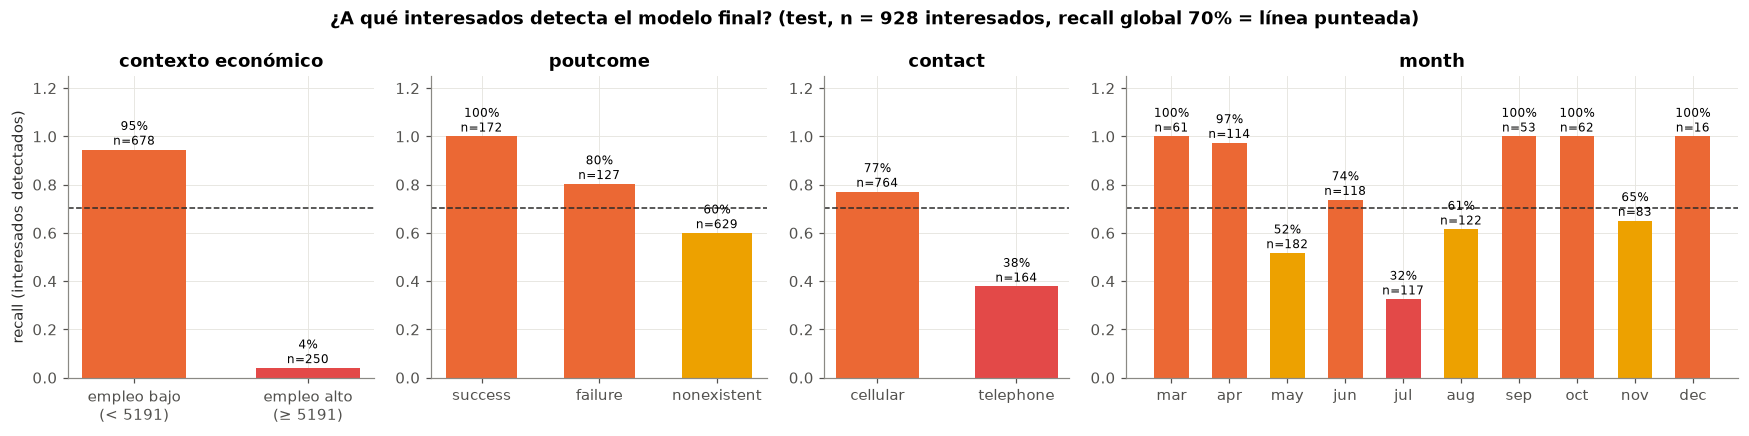

Falsos negativos: 277
  en contexto de empleo alto: 240 (87% de los FN)


In [3]:
X_test, y_test = cargar_split("test")
Xte = agregar_features(X_test)
pred = (final["modelo"].predict_proba(Xte[final["variables"]])[:, 1] >= final["umbral"]).astype(int)
inter = Xte.assign(detectado=pred)[y_test.values == 1]          # solo los interesados reales
ALTO_BAJO = ["empleo alto\n(≥ 5191)", "empleo bajo\n(< 5191)"]   # según nr.employed
inter["contexto económico"] = np.where(inter["nr.employed"] >= 5191, ALTO_BAJO[0], ALTO_BAJO[1])

def recall_por(col, orden=None):
    t = inter.groupby(col)["detectado"].agg(n="size", recall="mean")
    return t.reindex(orden) if orden else t.sort_values("n", ascending=False)

grupos = [("contexto económico", [ALTO_BAJO[1], ALTO_BAJO[0]]), ("poutcome", ["success", "failure", "nonexistent"]),
          ("contact", ["cellular", "telephone"]), ("month", None)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 1.1, 0.8, 2]})
for ax, (col, orden) in zip(axes, grupos):
    t = recall_por(col, orden)
    if col == "month":
        t = t.reindex(["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"])
    colores = [C_YES if r >= 0.7 else "#e34948" if r < 0.5 else "#eda100" for r in t["recall"]]
    ax.bar(t.index.astype(str), t["recall"], color=colores, width=0.6)
    for i, (r, n) in enumerate(zip(t["recall"], t["n"])):
        ax.text(i, r + 0.02, f"{r:.0%}\nn={n}", ha="center", fontsize=8)
    ax.axhline(inter["detectado"].mean(), ls="--", color="#2b2b2a", lw=1)
    ax.set(title=col, ylim=(0, 1.25), ylabel="recall (interesados detectados)" if col == grupos[0][0] else "")
fig.suptitle(f"¿A qué interesados detecta el modelo final? (test, n = {len(inter)} interesados, recall global "
             f"{inter['detectado'].mean():.0%} = línea punteada)", fontweight="bold")
guardar("23_errores_fn")

fn = inter[inter.detectado == 0]
print(f"Falsos negativos: {len(fn)}")
print(f"  en contexto de empleo alto: {(fn['nr.employed'] >= 5191).sum()} ({(fn['nr.employed'] >= 5191).mean():.0%} de los FN)")

**Hallazgo principal:** los falsos negativos **no están repartidos al azar**.
- **Contexto económico:** en los periodos de **empleo alto** (economía "buena", `nr.employed ≥ 5191`) el modelo detecta apenas al **4 %** de los interesados, contra el **95 %** en periodos de empleo bajo. Casi **9 de cada 10 FN** están en ese contexto. El modelo aprendió, en esencia, *"en épocas de economía fuerte casi nadie contrata, no llames"*. Es cierto en promedio (la tasa de `yes` ahí es mucho menor), pero hace que pierda a todos los interesados de esos periodos.
- **Mes:** se pierden muchos en `may` y `jul` (los meses con más llamadas y baja tasa de éxito); en `mar`, `sep`, `oct` y `dec` detecta al 100 %.
- **Tipo de contacto:** con teléfono fijo solo detecta al 38 % (la tasa base es baja, ~5 %).
- **Historial:** detecta al 100 % de quienes ya aceptaron en una campaña anterior (`poutcome = success`), pero solo al 60 % de quienes nunca fueron contactados (la gran mayoría).

**Conclusión:** el error más relevante son los **interesados en contextos "desfavorables" según el promedio** (economía fuerte, mayo/julio, teléfono fijo, sin historial). Para ellos el modelo prácticamente no usa el perfil del cliente, porque el contexto domina la decisión. Es la otra cara de la dependencia del contexto temporal vista en el Paso 2 (sin esas variables el AUC caía ~0.08) y en la importancia de variables (contexto ≈ 47 %).

### 5.5 Limitaciones del sistema

1. **Dependencia del contexto temporal.** Casi la mitad de la importancia del modelo viene de variables macroeconómicas y del mes. Los datos son de 2008–2010 (crisis financiera) y el split es aleatorio, así que train y test comparten los mismos periodos. En una campaña futura con un contexto económico distinto, el desempeño probablemente será **menor** al estimado (AUC 0.80).
2. **Interesados "invisibles" en contextos favorables:** en periodos de empleo alto el recall es ~4 %. Si la próxima campaña cae en un periodo así, el modelo casi no recomendaría llamar a nadie.
3. **Se pierde el 30 % de los interesados** incluso con el umbral bajo, y 7 de cada 10 llamadas siguen siendo a clientes que no contratan (precisión 0.30).
4. **Sin `duration`** (que no se puede usar antes de la llamada) el problema es intrínsecamente difícil: las clases están muy superpuestas y el techo de AUC de los 4 modelos ronda 0.80.
5. **Umbral elegido por un criterio geométrico** (punto más cercano a (0, 1)), no por los costos reales del banco (costo de una llamada vs. ganancia de un depósito), que no conocemos.
6. **Ajuste parcial de SVM:** por su costo computacional no se ajustaron `C` y `gamma` en conjunto, así que su comparación con el resto podría ser algo pesimista.

### 5.6 Mejoras propuestas

| Mejora | Motivo | ¿Visto en clase? |
|---|---|---|
| Elegir el umbral según **costos reales** (costo de llamada vs. ganancia por depósito) | Reemplaza el criterio geométrico por uno de negocio | Sí (trade-off del umbral, clase 4) |
| **Grid search** de RF (`max_depth` × `min_samples_leaf` × `max_features`) en el rango acotado por las curvas | Las curvas se hicieron de a un hiperparámetro | Sí (clase 7) |
| Ajustar `C` y `gamma` de SVM **en conjunto** | Se ajustan juntos en RBF | Sí (clase 8) |
| **Combinar RF y KNN** (promedio de probabilidades) | RF captura patrones globales y KNN locales; cometen errores distintos | Sí (clase 7, *blending*) |
| Quitar `contactado_antes` o `poutcome` (redundantes) y aplicar selección de variables (RFE, importancia) | Menos ruido para NB y KNN | Sí (clases 3 y 7) |
| Naive Bayes con atributos **categóricos** (frecuencias + Laplace) en lugar de gaussianas sobre one-hot | Respeta mejor la naturaleza de las variables | Sí (clase 6) |
| Validar con un **split temporal** (entrenar con meses anteriores, evaluar en posteriores) | Estimación más realista para campañas futuras | No (propuesta) |
| Variables de contexto **relativas** (p. ej. tasa de éxito reciente de la campaña) o modelos separados por contexto económico | Reducir la dependencia del periodo y recuperar a los interesados en contextos "buenos" | No (propuesta) |
| Más información del cliente (saldo, productos contratados, historial de transacciones) | Que el perfil del cliente pese más que el contexto | — |

### 5.7 Mensaje final

- Con un **Random Forest** (`max_depth = 10`, 50 árboles, 14 variables) y un **umbral ajustado a 0.083**, el banco puede **llamar al 26 % de los clientes y captar al 70 % de los interesados**, con una tasa de éxito por llamada **2.7 veces mayor** que sin modelo (30 % vs. 11 %). Rendimiento en test: **AUC 0.81, recall 0.70**, consistente con lo estimado por validación cruzada.
- El modelo funcionó mejor que NB, KNN y SVM porque **no impone supuestos** que estos datos violan (independencia, normalidad, linealidad, escala) y porque capta **interacciones** entre el cliente y el contexto.
- Su principal debilidad es que **depende mucho del momento económico**: casi todos los interesados que pierde fueron contactados en periodos de economía fuerte. Antes de usarlo en una campaña nueva convendría validarlo con datos de un periodo posterior.